# Avance 4 — Red convolutiva: clasificación de 104 flores

## 1. Introducción y objetivo
Continuar el Entregable 3 corregido: allí se desarrolló una CNN de cuatro bloques (480,936 parámetros) y se estudió el conjunto completo, muestras aleatorias reducidas y datos sintéticos de Distribution Matching (DM). También se documentaron hiperparámetros y regularización. Aquí se incorpora una MLP de referencia reconstruida posteriormente, se comparan CNN de cuatro/seis convoluciones y se amplían regularización y evaluación por clase. El A3 corregido usa una CNN, no una MLP.

**Familia A3:** CNN inicial y reducción/DM. **Familia A4:** cuatro corridas PyTorch/DirectML históricas. **Familia F:** hiperparámetros TensorFlow/Metal reutilizados en el A3 corregido y conservados en el reporte final; aquí se profundiza su par de regularización. Las copias A3/F son la misma evidencia, no repeticiones independientes.

El modo predeterminado lee evidencia y no entrena. Se recalculan F1, exactitud, métricas por clase y matrices desde predicciones. Pérdidas y train limpio se cotejan con históricos; no se repite inferencia sobre TFRecords. Una semilla y validación usada para selección no permiten afirmar significancia estadística ni desempeño independiente de test.

In [1]:
%matplotlib inline
from pathlib import Path
import ast, hashlib, importlib.util, json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/model.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
REPORT = ROOT / "reports/entregable_4"
A4 = REPORT / "avance4_2026-10-21"
F = ROOT / "reports/final/experimentos"
RUN_TRAINING = False
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":10,
                     "axes.spines.top":False, "axes.spines.right":False})
print("Modo evidencia histórico. RUN_TRAINING =", RUN_TRAINING)

Modo evidencia histórico. RUN_TRAINING = False


### Continuidad experimental respecto al Entregable 3

1. CNN inicial A3: Adam 1e-3, batch 32, entrada RGB 112×112, F1 macro 0.5538 y exactitud 61.61%, checkpoint 38/43.
2. Reducción/DM: IPC 1 y 10, tres semillas de clasificador por modalidad; un conjunto sintético por IPC compartido. F1 medio DM/aleatorio: 0.0672/0.0514 con IPC1 y 0.2044/0.2575 con IPC10. No se usaron imágenes DM en las cuatro corridas principales A4.
3. Hiperparámetros y regularización F ya documentados en A3: referencia 0.5784, LR3e-4 0.4605, dropout 0.3 0.5596 y control 0.5332. Sus archivos duplicados no suman entrenamientos.
4. A4 amplía MLP/CNN y profundidad, con ejecuciones diferentes y batch 64 DirectML. La CNN original conserva la arquitectura A3; F1 0.5740 no continúa el checkpoint 0.5538 ni prueba mejora arquitectónica.
5. Evaluación detallada del seleccionado A4 (checkpoint 61), con las104 clases.

Es una progresión académica de preguntas. El A3 corregido incorporó F después de las corridas históricas A4 del21 de octubre; no implica ese orden literal de ejecución. El antiguo alias H del plan equivale a A3; sus hiperparámetros pertenecen a F. Matriz completa: `reports/entregable_4/ALINEACION_AVANCE3_AVANCE4.md`.

La siguiente celda solo lee las fuentes: verifica13 clasificadores A3, las ocho copias idénticas A3/F, parámetros por cálculo y hashes del A3 intacto. No ejecuta el notebook A3 ni escribe en sus carpetas.

In [2]:
from scripts.check_avance3_avance4 import inspect, verify_frozen_a3
provenance = inspect()
frozen = json.loads((REPORT/"alineacion_avance3/procedencia.json").read_text(encoding="utf-8"))
verify_frozen_a3(frozen)
print("A3 intacto; clasificadores:", provenance["a3_classifiers_checked"])
display(pd.DataFrame([
    {"familia":"A3", "fuente":"reports/entregable_3/runs", "uso":"CNN inicial y reducción/DM; 13 clasificadores"},
    {"familia":"F", "fuente":"reports/final/experimentos/runs; alias A3/hiperparametros", "uso":"4 corridas de hiperparámetros, sin duplicar alias; par de regularización"},
    {"familia":"A4", "fuente":"reports/entregable_4/avance4_2026-10-21/runs", "uso":"4 corridas DirectML; selección solo dentro de A4"}
]))
print("Pérdida mínima del historial y pérdida del checkpoint F1 son cantidades distintas:")
display(pd.DataFrame(provenance["loss_definitions"]).round(6))

A3 intacto; clasificadores: 13


,familia,fuente,uso
0,A3,reports/entregable_3/runs,CNN inicial y reducción/DM; 13 clasificadores
1,F,reports/final/experimentos/runs; alias A3/hipe...,"4 corridas de hiperparámetros, sin duplicar al..."
2,A4,reports/entregable_4/avance4_2026-10-21/runs,4 corridas DirectML; selección solo dentro de A4


Pérdida mínima del historial y pérdida del checkpoint F1 son cantidades distintas:


,experiment_id,checkpoint_epoch,checkpoint_val_loss,minimum_loss_epoch,minimum_val_loss
0,F/referencia,91,1.482972,54,1.463671
1,F/sin_regularizacion,34,2.039544,25,1.824678
2,F/lr_3e-4,98,1.782709,107,1.775750
3,F/dropout_0.3,61,1.627200,47,1.595555


## 2. Carga y preparación de datos
Se mantienen train=12,753, val=3,712 y test=7,382 sin etiquetas locales. Origen JPEG 224×224 → RGB float32/255 → bilineal con antialias a 112×112. Aumentos de train: flip horizontal, rotación 0.05, zoom 0.1 y contraste 0.1. Validación sin aumentos. Se emplean las 104 clases en F1 macro, incluidos ceros.

Sin TFRecords, este modo carga conteos, históricos y predicciones guardados, no imágenes nuevas. La misma secuencia de etiquetas apoya consistencia, pero sin IDs/TFRecords no vuelve a certificar la identidad de cada imagen.

In [3]:
counts = pd.read_csv(F / "conteo_por_clase.csv")
assert counts.train.sum()==12753 and counts.val.sum()==3712 and len(counts)==104
print("Train y val por clase (muestra):")
display(counts.head())
print("Train por clase: mínimo", counts.train.min(), "máximo", counts.train.max())
data_path = ROOT / "data/raw/tpu-getting-started/tfrecords-jpeg-224x224"
print("TFRecords locales:", len(list(data_path.rglob("*.tfrec"))))
print("Frameworks disponibles:", {m:importlib.util.find_spec(m) is not None
       for m in ["tensorflow","keras","torch","torch_directml"]})

Train y val por clase (muestra):


,label,name,train,val
0,0,pink primrose,272,79
1,1,hard-leaved pocket orchid,26,7
2,2,canterbury bells,20,6
3,3,sweet pea,21,6
4,4,wild geranium,703,205


Train por clase: mínimo 18 máximo 782
TFRecords locales: 0
Frameworks disponibles: {'tensorflow': False, 'keras': False, 'torch': False, 'torch_directml': False}


## 3. Definición de arquitecturas
MLP: Flatten 37,632 → Dense256/ReLU → Dropout0.5 → Dense104 logits (9,660,776 parámetros). CNN original: cuatro Conv3×3 (32/64/128/256), ReLU y Pool2×2, GAP, Dense256/ReLU, Dropout0.5 y Dense104 (480,936). CNN ampliada: añade Conv128 tras pool3 y Conv256 tras pool4 (1,218,600).

Se muestran las definiciones reales del código sin importar frameworks. Son código de construcción, no una ejecución del modelo en esta celda.

def _conv_stack(x, architecture="baseline", l2=0.0):
    """Cuatro poolings, con convoluciones adicionales o BatchNorm según la variante."""
    if architecture not in EXTRA_CONV_STAGES:
        raise ValueError(f"Arquitectura desconocida: {architecture}")
    for i, f in enumerate(FILTERS, start=1):
        normalized = architecture == "batchnorm"
        x = layers.Conv2D(f, 3, padding="same", activation=None if normalized else "relu",
                          use_bias=not normalized, kernel_regularizer=_regularizer(l2), name=f"conv{i}")(x)
        if normalized:
            x = layers.BatchNormalization(axis=-1, epsilon=BATCHNORM_EPSILON,
                                           momentum=BATCHNORM_MOMENTUM, name=f"bn{i}")(x)
            x = layers.ReLU(name=f"relu{i}")(x)
        x = layers.MaxPooling2D(2, name=f"pool{i}")(x)
        if i in EXTRA_CONV_STAGES[architecture]:
            x = layers.Conv2D(f, 3, padding="same", activation="relu",
                              kernel

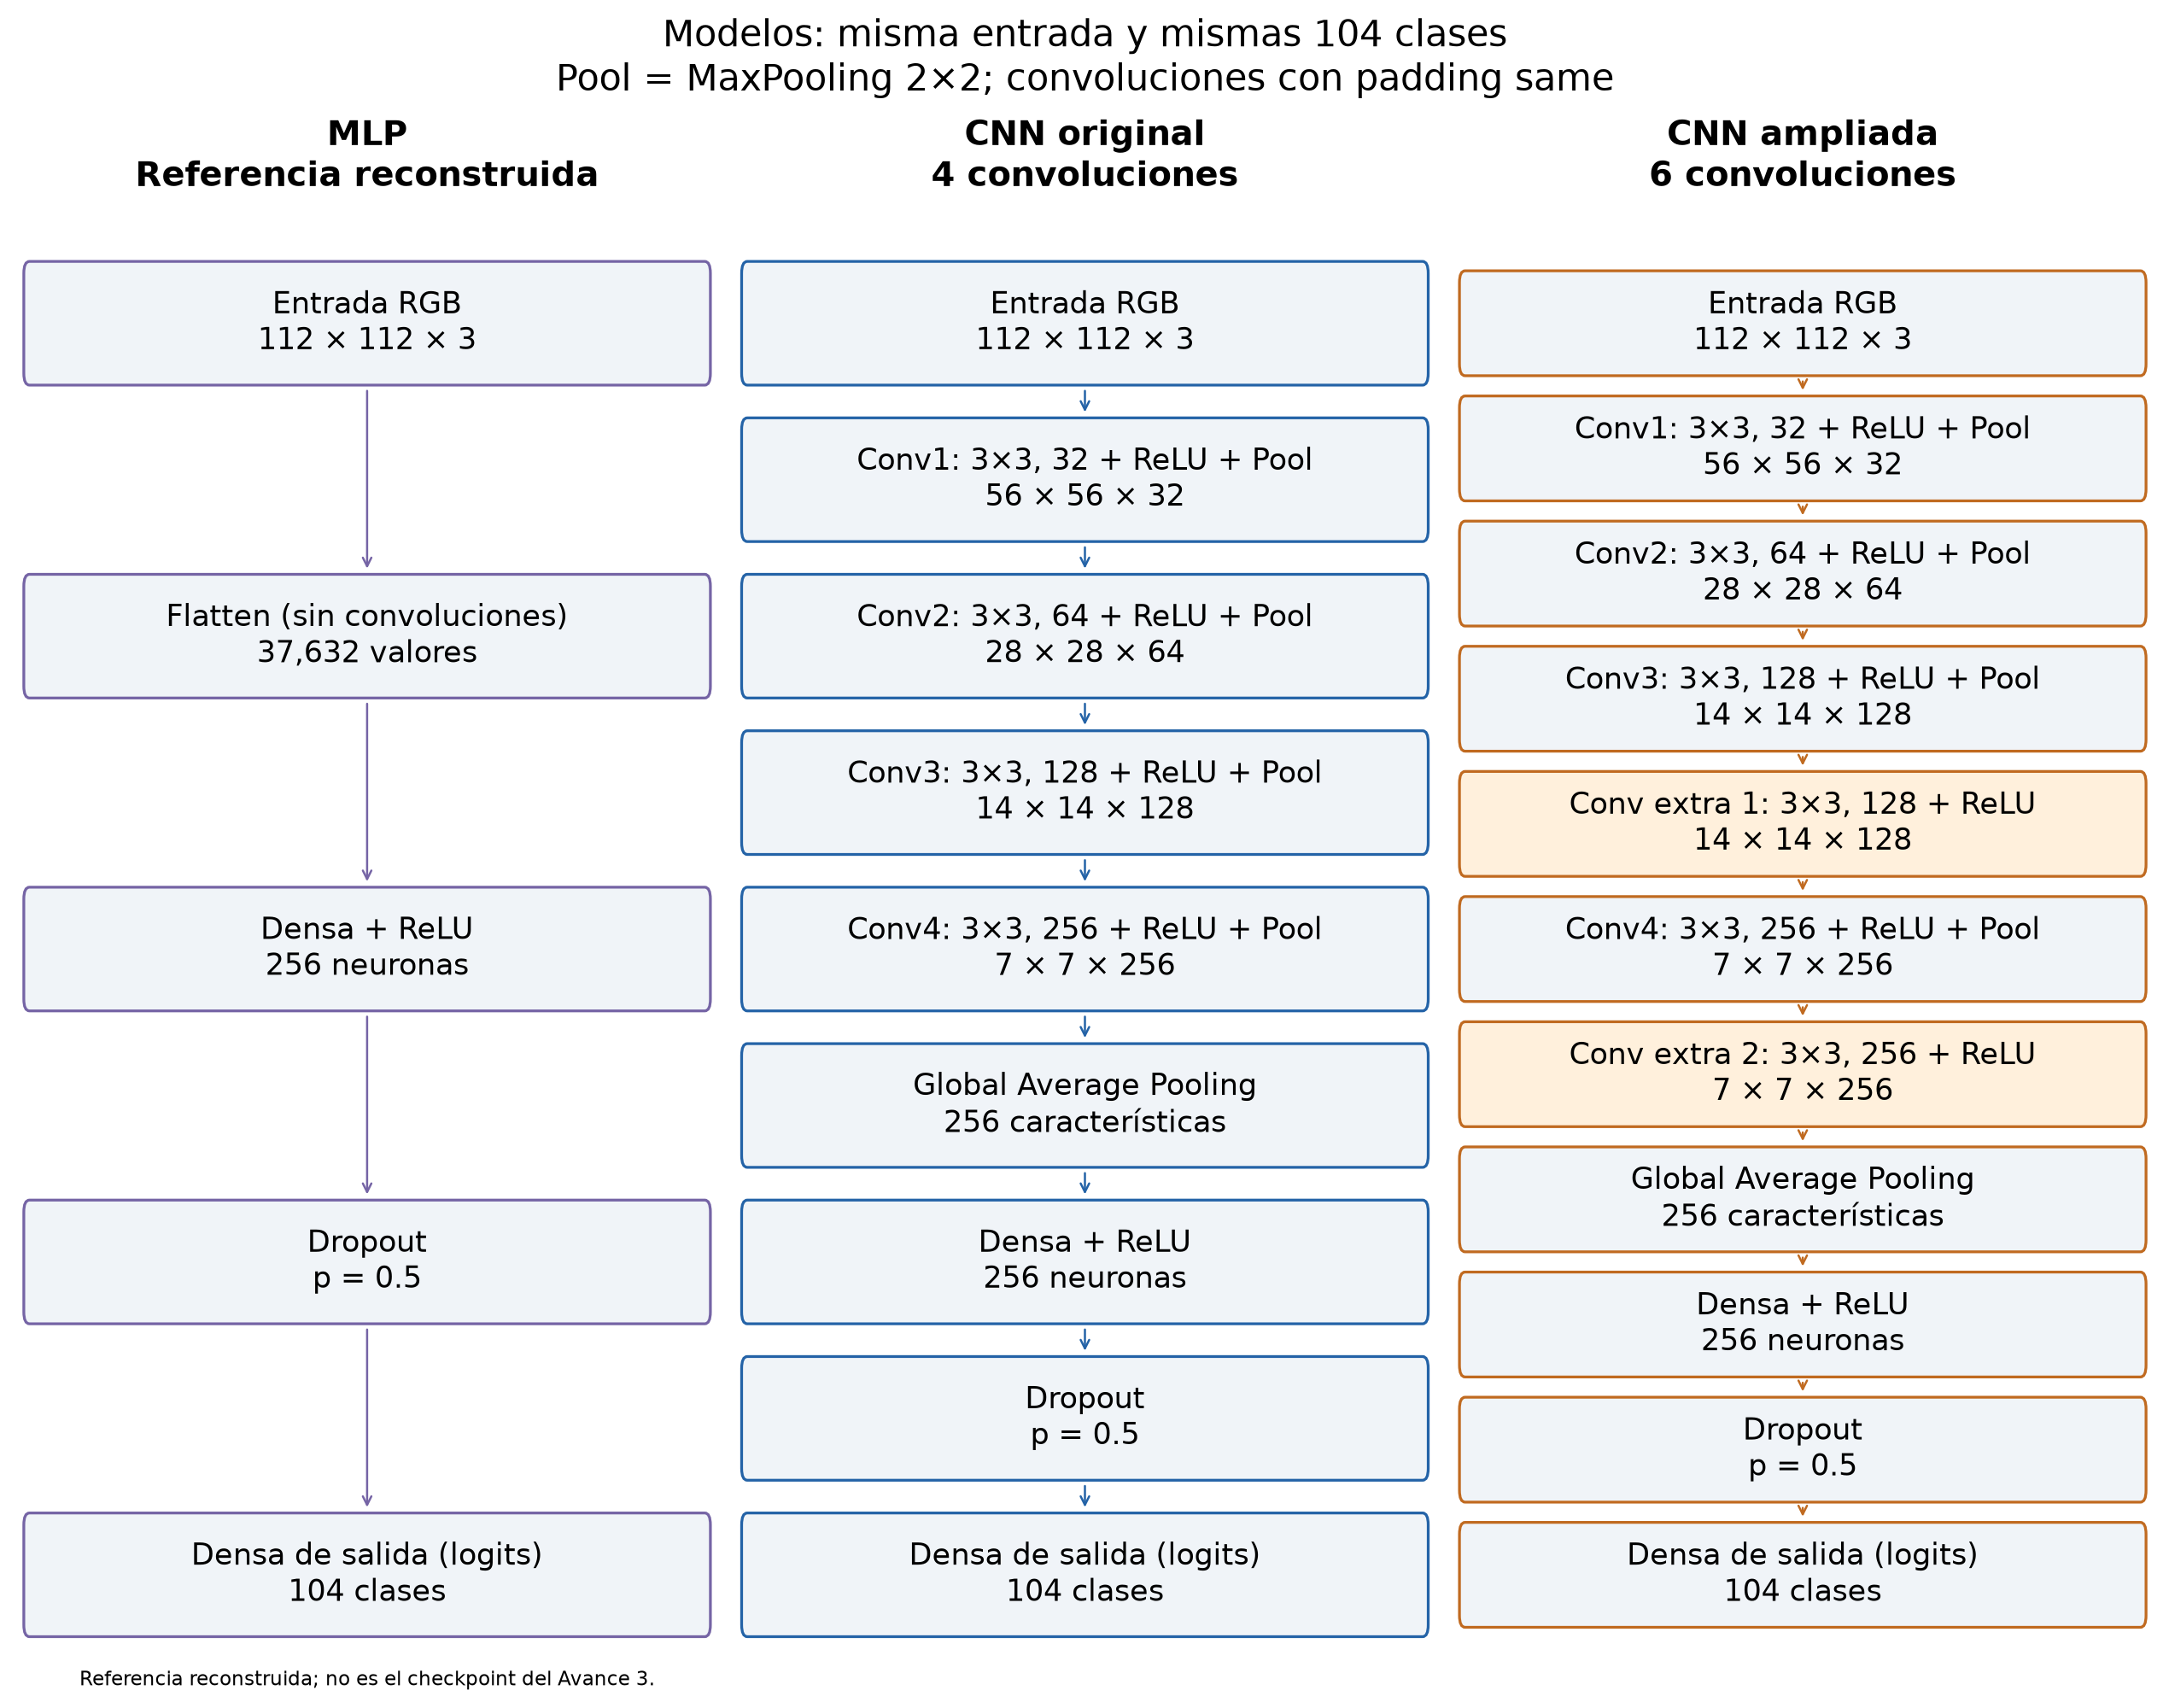

In [4]:
def show_definition(relative, names):
    source = (ROOT / relative).read_text(encoding="utf-8-sig")
    tree = ast.parse(source)
    for node in tree.body:
        if isinstance(node,(ast.FunctionDef,ast.ClassDef)) and node.name in names:
            print(ast.get_source_segment(source,node), "\n")
show_definition("src/model.py", {"build_mlp","build_cnn","_conv_stack"})
show_definition("src/train_mlp_reference.py", {"FlowerMLP"})
display(Image(filename=str(A4/"figures/arquitecturas.png"),width=1000))

## 4. Configuración de entrenamiento y modo opcional
Todos los A4 usan batch 64, seed 0, hasta 150 épocas, dropout 0.5 y aumentos. Original/ampliada: Adam LR 1e-3, paciencia 5. MLP: Adam LR 1e-4, paciencia 10 y mínimo 10 épocas. CNN AdamW: WD 0.01 sin sesgos, scheduler val_loss factor 0.5/paciencia 2/mínimo 1e-5, parada 12. Se selecciona máximo F1 macro, no máximo independiente de exactitud.

**Entrenar requiere datos y frameworks compatibles.** La celda siguiente está desactivada y escribe en una carpeta nueva con fecha; no utiliza las rutas absolutas de las configuraciones históricas ni sobrescribe sus resultados. El backend histórico es DirectML, por lo que otro equipo no garantiza igualdad bit a bit. Una ejecución nueva debe evaluarse/identificarse por separado y no sustituye los números de este notebook.

In [5]:
if RUN_TRAINING:
    from datetime import datetime
    missing = [m for m in ["tensorflow","keras","torch","torch_directml"]
               if importlib.util.find_spec(m) is None]
    if missing or not list((data_path/"train").glob("*.tfrec")) or not list((data_path/"val").glob("*.tfrec")):
        raise RuntimeError("Entrenamiento no disponible: faltan frameworks o TFRecords: " + str(missing))
    new_output = REPORT / ("avance4_repeticion_"+datetime.now().strftime("%Y%m%d_%H%M%S"))
    if new_output.exists():
        raise FileExistsError("Elegir una salida nueva para conservar evidencia")
    subprocess.run([sys.executable,"-m","scripts.run_avance4","--output",str(new_output)],cwd=ROOT,check=True)
    subprocess.run([sys.executable,"-m","src.train_mlp_reference","--config",str(new_output/"cnn_original.yaml"),
                    "--output",str(new_output),"--lr","0.0001","--patience","10","--min-epochs","10"],cwd=ROOT,check=True)
    subprocess.run([sys.executable,"-m","scripts.prepare_avance4","--output",str(new_output)],cwd=ROOT,check=True)
    print("Nueva evidencia separada:",new_output)
else:
    print("No se entrenó: se continúa exclusivamente con los archivos históricos.")

No se entrenó: se continúa exclusivamente con los archivos históricos.


## 5. Evidencia de experimentos y verificación
Las cuatro corridas A4 tienen predicciones, matriz, history, summary y checkpoints históricos. Se recalculan las métricas; las épocas de history empiezan en 0 y las de checkpoint en 1. El par F se verifica también al cargarlo. No se revalidan logits ni inferencia de checkpoints en este modo.

In [6]:
from scripts.analyze_mlp_avance4 import SPECS, validate_saved_predictions
from reports.entregable_4.correcciones_etapa3.analizar_regularizacion import load_evidence
rows, histories, predictions_by_id = [], {}, {}
shared_true = None
for identifier, name, family, variant, run, lr in SPECS[:4]:
    directory = ROOT / family / "runs" / variant / run
    summary = json.loads((directory/"summary.json").read_text(encoding="utf-8"))
    report = json.loads((directory/"eval_report.json").read_text(encoding="utf-8"))
    pred = pd.read_csv(directory/"evaluation/validation_predictions.csv")
    cm = pd.read_csv(directory/"evaluation/confusion_matrix.csv",index_col=0).to_numpy()
    history = pd.read_csv(directory/"history.csv")
    metrics = validate_saved_predictions(pred,cm,report,summary,history)
    assert len(pred)==3712
    if shared_true is not None: np.testing.assert_array_equal(shared_true,pred.true_label)
    shared_true = pred.true_label.to_numpy()
    rows.append({"experiment_id":identifier,"modelo":name,"parametros":summary["parameters"],
                 "checkpoint":summary["best_epoch"],"epocas":summary["epochs_run"],"lr_inicial":lr,
                 "exactitud":metrics["accuracy"],"f1_macro":metrics["f1_macro"],"loss_guardada":report["val_loss"]})
    histories[identifier] = history
    predictions_by_id[identifier] = pred
results = pd.DataFrame(rows)
reg_runs, reg_table, common_epochs, reg_sources = load_evidence()
print("Verificadas: cuatro A4 y dos F. Épocas comunes F:",common_epochs[0],"a",common_epochs[-1])
display(results.round(6))

Verificadas: cuatro A4 y dos F. Épocas comunes F: 1 a 46


,experiment_id,modelo,parametros,checkpoint,epocas,lr_inicial,exactitud,f1_macro,loss_guardada
0,A4_MLP_lr1e4,MLP histórica A4,9660776,77,87,0.0001,0.155172,0.028013,3.403151
1,A4_CNN_original,CNN original A4,480936,53,58,0.0010,0.632543,0.573954,1.519583
2,A4_CNN_deep,CNN ampliada A4,1218600,46,51,0.0010,0.622306,0.550151,1.785698
3,A4_CNN_AdamW,CNN AdamW + LR A4,480936,61,73,0.0010,0.644397,0.574474,1.507477


## 6. Comparación MLP/CNN y profundidad
La MLP histórica predice 21 clases y concentra 85.24% de las predicciones en cinco; 87 clases tienen F1 cero. Su train online tiene baja exactitud, pero no hay F1 limpio de train para esa corrida. El diagnóstico es ajuste insuficiente con posibles problemas de optimización, no incapacidad universal de las MLP para aprender imágenes.

La conectividad local, filtros compartidos y pooling/GAP reducen parámetros y aprovechan estructura espacial en las CNN. La comparación no aísla arquitectura: cambian capacidad, LR y paciencia. La ampliada ajusta más train y muestra deterioro de pérdida val, compatible con mayor sobreajuste en esta configuración y semilla.

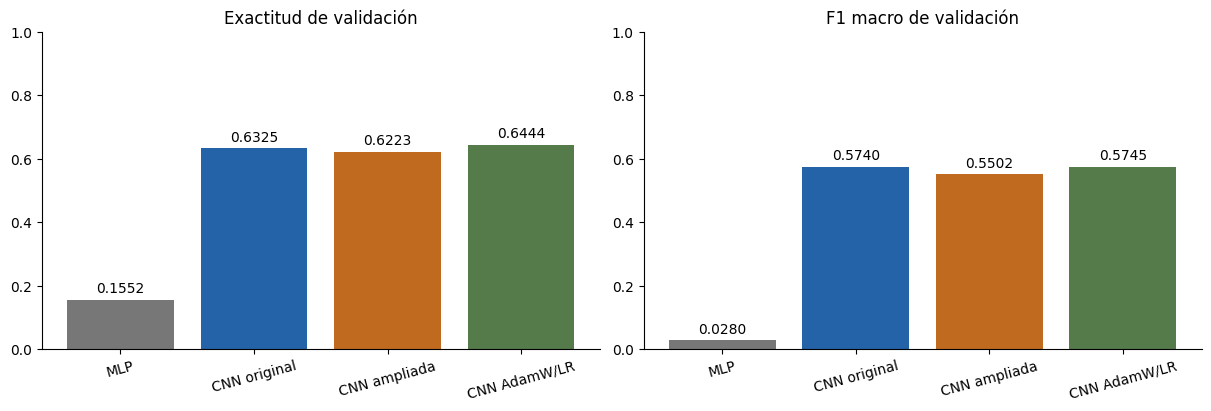

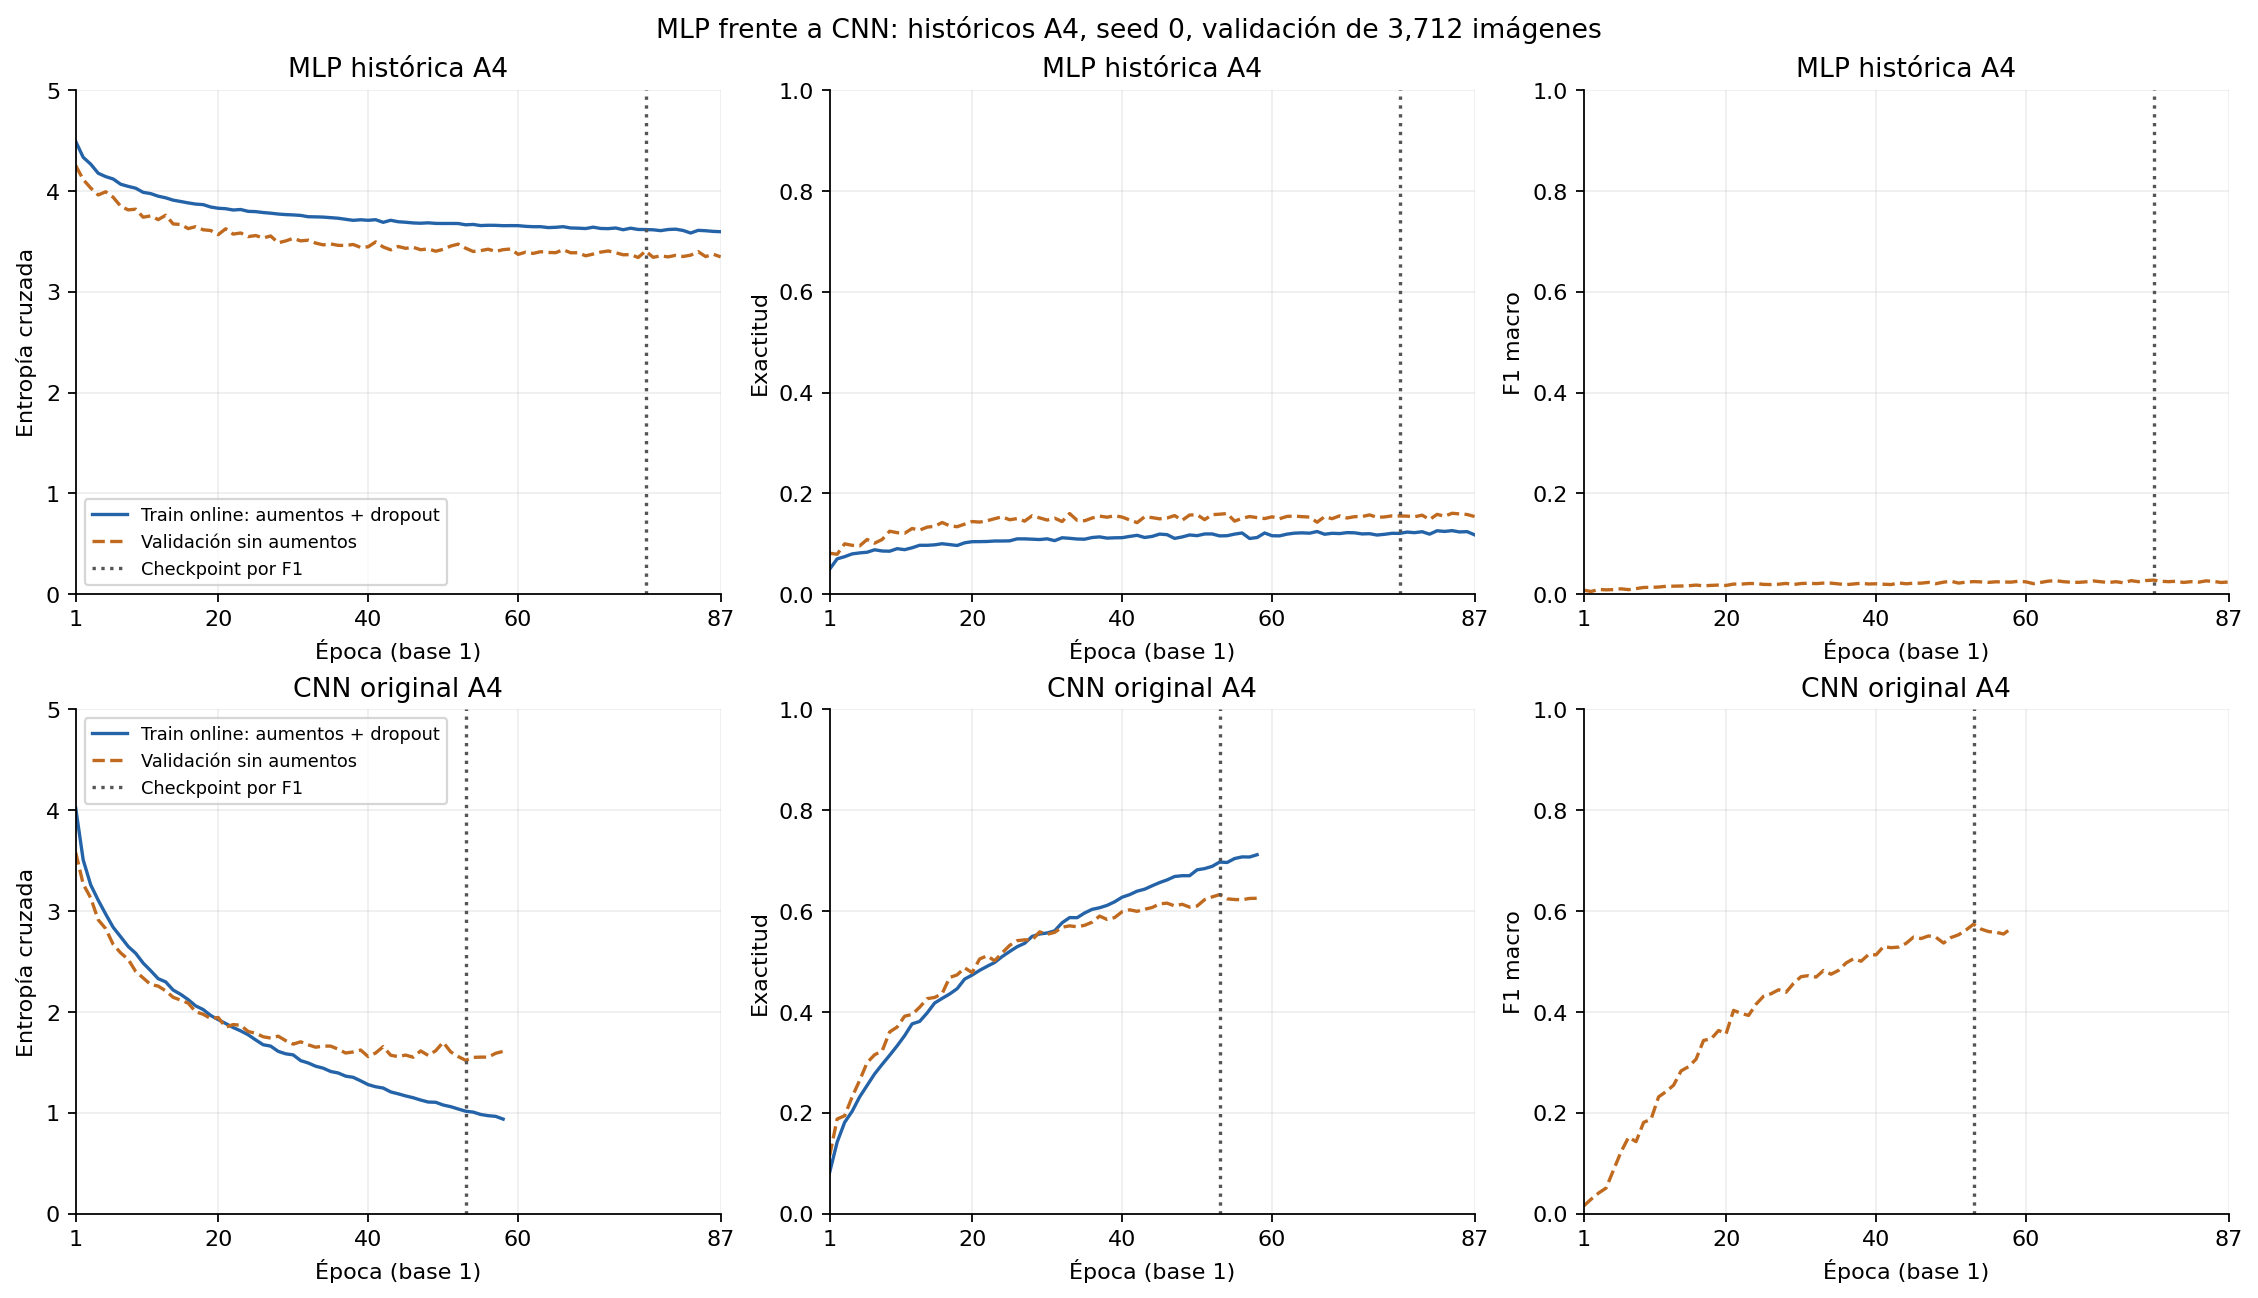

MLP → CNN original, diferencia de exactitud (pp): 47.737068965517246
MLP → CNN original, diferencia de F1: 0.5459410814194222


In [7]:
fig,axes = plt.subplots(1,2,figsize=(12,4),layout="constrained")
labels = ["MLP","CNN original","CNN ampliada","CNN AdamW/LR"]
for ax,field,title in zip(axes,["exactitud","f1_macro"],["Exactitud de validación","F1 macro de validación"]):
    bars=ax.bar(labels,results[field],color=["#777777","#2463a7","#c06a20","#567b4b"])
    ax.bar_label(bars,labels=[f"{v:.4f}" for v in results[field]],padding=3)
    ax.set(title=title,ylim=(0,1));ax.tick_params(axis="x",rotation=15)
plt.show()
display(Image(filename=str(REPORT/"correcciones_etapa2/curvas_mlp_cnn.png"),width=1000))
indexed=results.set_index("experiment_id")
print("MLP → CNN original, diferencia de exactitud (pp):",100*(indexed.loc["A4_CNN_original","exactitud"]-indexed.loc["A4_MLP_lr1e4","exactitud"]))
print("MLP → CNN original, diferencia de F1:",indexed.loc["A4_CNN_original","f1_macro"]-indexed.loc["A4_MLP_lr1e4","f1_macro"])

## 7. Regularización: familia F complementaria
Se profundiza la misma evidencia de regularización ya documentada en el A3 corregido, conservada también en F. Se compara F/referencia (dropout 0.5, aumentos, AdamW/WD 0.01) con F/sin_regularizacion (dropout 0, sin aumentos, Adam/WD 0). Ambas conservan parada temprana y reducción de LR. Train limpio se midió históricamente sobre 3,712 imágenes fijas sin aumentos y con `training=False`; no es todo train ni una muestra estratificada.

Primero se comparan checkpoints seleccionados (91/103 y 34/46); después se extrae **exactamente la época 34** de ambas corridas. Se conservan ambos análisis y no se interpolan datos. Las brechas se restan con precisión completa dentro de la misma fila. La pérdida aquí es la del checkpoint por F1: 1.4830/2.0395. El A3 registra también mínimos de historial (1.4637 en54 y1.8247 en25), compatibles pero distintos. La tabla de procedencia anterior muestra ambos valores y épocas para las cuatro corridas F.

In [8]:
fields=["experiment_id","epoch","train_f1_macro","val_f1_macro","train_eval_accuracy","val_accuracy","train_eval_loss","val_loss","gap_f1"]
print("Mejores checkpoints:")
display(reg_table[reg_table.comparison=="selected_checkpoint"][fields].round(6))
print("Época común34:")
display(reg_table[reg_table.comparison=="common_epoch_34"][fields].round(6))
best=reg_table[reg_table.comparison=="selected_checkpoint"].reset_index(drop=True)
print("Delta F1 con − sin:",best.loc[0,"val_f1_macro"]-best.loc[1,"val_f1_macro"])
print("Delta exactitud(pp):",100*(best.loc[0,"val_accuracy"]-best.loc[1,"val_accuracy"]))
print("Reducción brecha F1:",best.loc[1,"gap_f1"]-best.loc[0,"gap_f1"])

Mejores checkpoints:


,experiment_id,epoch,train_f1_macro,val_f1_macro,train_eval_accuracy,val_accuracy,train_eval_loss,val_loss,gap_f1
0,F/referencia,91,0.813796,0.578367,0.830011,0.640625,0.557136,1.482972,0.235430
1,F/sin_regularizacion,34,0.876664,0.533212,0.873384,0.596444,0.443445,2.039544,0.343453


Época común34:


,experiment_id,epoch,train_f1_macro,val_f1_macro,train_eval_accuracy,val_accuracy,train_eval_loss,val_loss,gap_f1
2,F/referencia,34,0.579326,0.485109,0.642241,0.569774,1.224729,1.628926,0.094217
3,F/sin_regularizacion,34,0.876664,0.533212,0.873384,0.596444,0.443445,2.039544,0.343453


Delta F1 con − sin: 0.0451550760215661
Delta exactitud(pp): 4.418103448275867
Reducción brecha F1: 0.10802311515890362


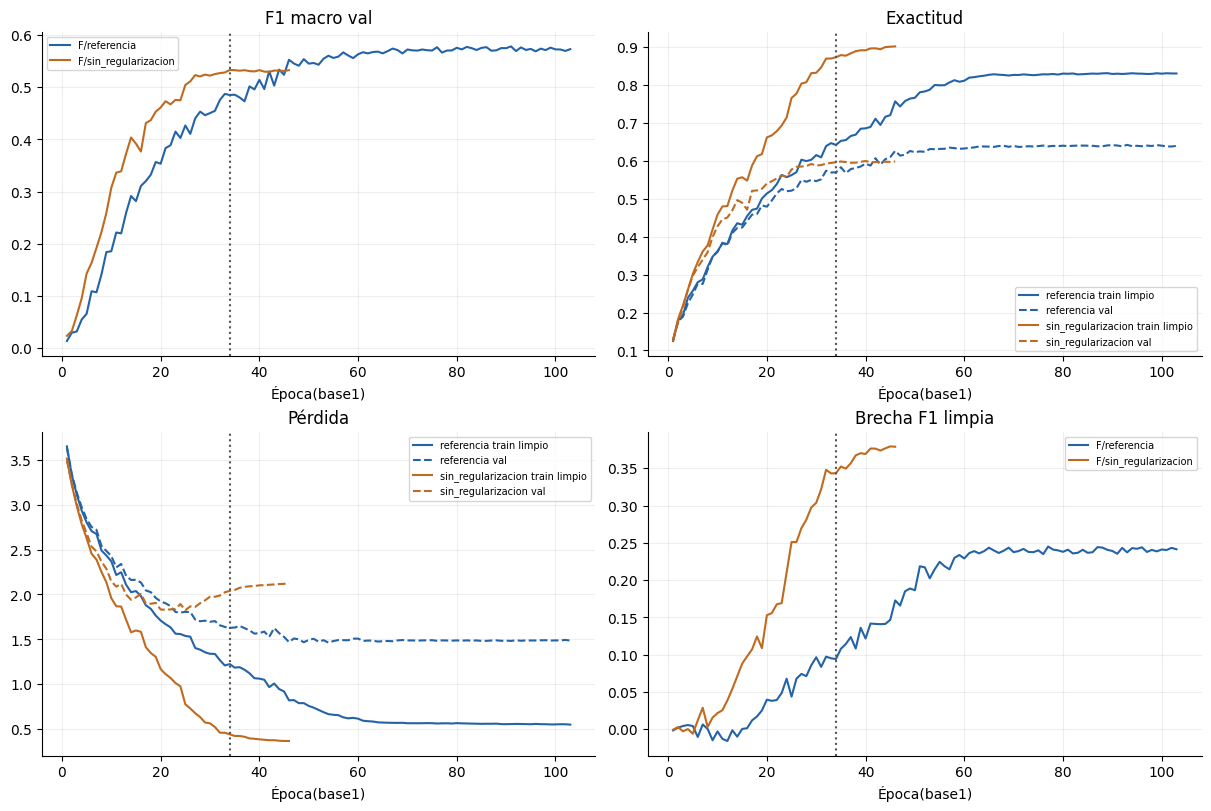

In [9]:
fig,axes=plt.subplots(2,2,figsize=(12,8),layout="constrained")
for key,color in [("referencia","#2463a7"),("sin_regularizacion","#c06a20")]:
    h=reg_runs[key]["history"];x=h.epoch+1
    axes[0,0].plot(x,h.val_f1_macro,color=color,label="F/"+key)
    axes[0,1].plot(x,h.train_eval_accuracy,color=color,label=key+" train limpio")
    axes[0,1].plot(x,h.val_accuracy,color=color,ls="--",label=key+" val")
    axes[1,0].plot(x,h.train_eval_loss,color=color,label=key+" train limpio")
    axes[1,0].plot(x,h.val_loss,color=color,ls="--",label=key+" val")
    axes[1,1].plot(x,h.train_f1_macro-h.val_f1_macro,color=color,label="F/"+key)
for ax,title in zip(axes.flat,["F1 macro val","Exactitud","Pérdida","Brecha F1 limpia"]):
    ax.axvline(34,color="#555555",ls=":")
    ax.set(title=title,xlabel="Época(base1)");ax.legend(fontsize=7);ax.grid(alpha=.2)
plt.show()

La intervención conjunta mejora los mejores modelos: F1 val+0.045155 y exactitud +4.4181pp; brecha F1 de 0.3435 a 0.2354. Sin regularización explícita el ajuste de train es mayor pero val es peor, compatible con sobreajuste.

**Matiz de época 34:** sin regularización tiene mayor F1 val (0.5332 frente a 0.4851) y exactitud (59.64% frente a56.98%), pero mayor pérdida (2.0395 frente a 1.6289) y brecha (0.3435 frente a 0.0942). La regularizada sigue mejorando después. En34 sus LR difieren; misma época no implica un ensayo completamente controlado. No se atribuye el efecto a una técnica individual ni se afirma significancia con una semilla.

## 8. Evaluación del seleccionado A4 y métricas por clase
Se elige máximo F1 únicamente entre los cuatro A4: CNN AdamW/LR, checkpoint 61/73, F1 macro 0.574474 y exactitud 64.4397%. La referencia F de regularización no sustituye a ese seleccionado. Se recalculan precisión, recall, F1 y soporte de 104 clases y se reconcilian con CSV de entrega.

In [10]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
selected=results.loc[results.f1_macro.idxmax()]
assert selected.experiment_id=="A4_CNN_AdamW" and selected.checkpoint==61
pred=predictions_by_id[selected.experiment_id]
precision,recall,f1,support=precision_recall_fscore_support(pred.true_label,pred.predicted_label,labels=range(104),zero_division=0)
classes=pd.DataFrame({"label":range(104),"precision":precision,"recall":recall,"f1":f1,"support":support}).merge(counts[["label","name"]],on="label")
saved=pd.read_csv(REPORT/"correcciones_etapa4/metricas_seleccionado.csv")
np.testing.assert_allclose(classes[["precision","recall","f1","support"]],saved[["precision","recall","f1","support"]],atol=1e-14)
cm=confusion_matrix(pred.true_label,pred.predicted_label,labels=range(104))
assert cm.sum()==3712 and cm.trace()==2392 and abs(f1.mean()-selected.f1_macro)<1e-14
print("Seleccionado:",selected.experiment_id,"| aciertos:",cm.trace(),"/",cm.sum())
print("Precisión macro:",precision.mean(),"| recall macro:",recall.mean(),"| F1macro:",f1.mean())
display(pd.concat([classes.sort_values(["f1","label"],ascending=[False,True]).head(5),classes.sort_values(["f1","label"]).head(5)]))
print("Tabla completa: reports/entregable_4/correcciones_etapa4/metricas_seleccionado.csv y anexo PDF")

Seleccionado: A4_CNN_AdamW | aciertos: 2392 / 3712
Precisión macro: 0.6214684170187184 | recall macro: 0.5634652236613092 | F1macro: 0.5744742345749192


,label,precision,recall,f1,support,name
60,60,1.000000,1.0,1.000000,8,cautleya spicata
63,63,1.000000,1.0,1.000000,8,silverbush
59,59,0.944444,1.0,0.971429,17,pink-yellow dahlia
65,65,0.900000,1.0,0.947368,9,osteospermum
64,64,0.888889,1.0,0.941176,16,californian poppy
2,2,0.000000,0.0,0.000000,6,canterbury bells
3,3,0.000000,0.0,0.000000,6,sweet pea
31,31,0.000000,0.0,0.000000,7,garden phlox
38,38,0.000000,0.0,0.000000,5,siam tulip
44,44,0.000000,0.0,0.000000,5,bolero deep blue


Tabla completa: reports/entregable_4/correcciones_etapa4/metricas_seleccionado.csv y anexo PDF


,true_label,predicted_label,true,predicted,count
0,30,73,carnation,rose,12
1,102,73,common tulip,rose,12
2,79,73,anthurium,rose,10
3,48,49,daisy,common dandelion,8
4,68,103,windflower,wild rose,8
5,95,73,camellia,rose,8


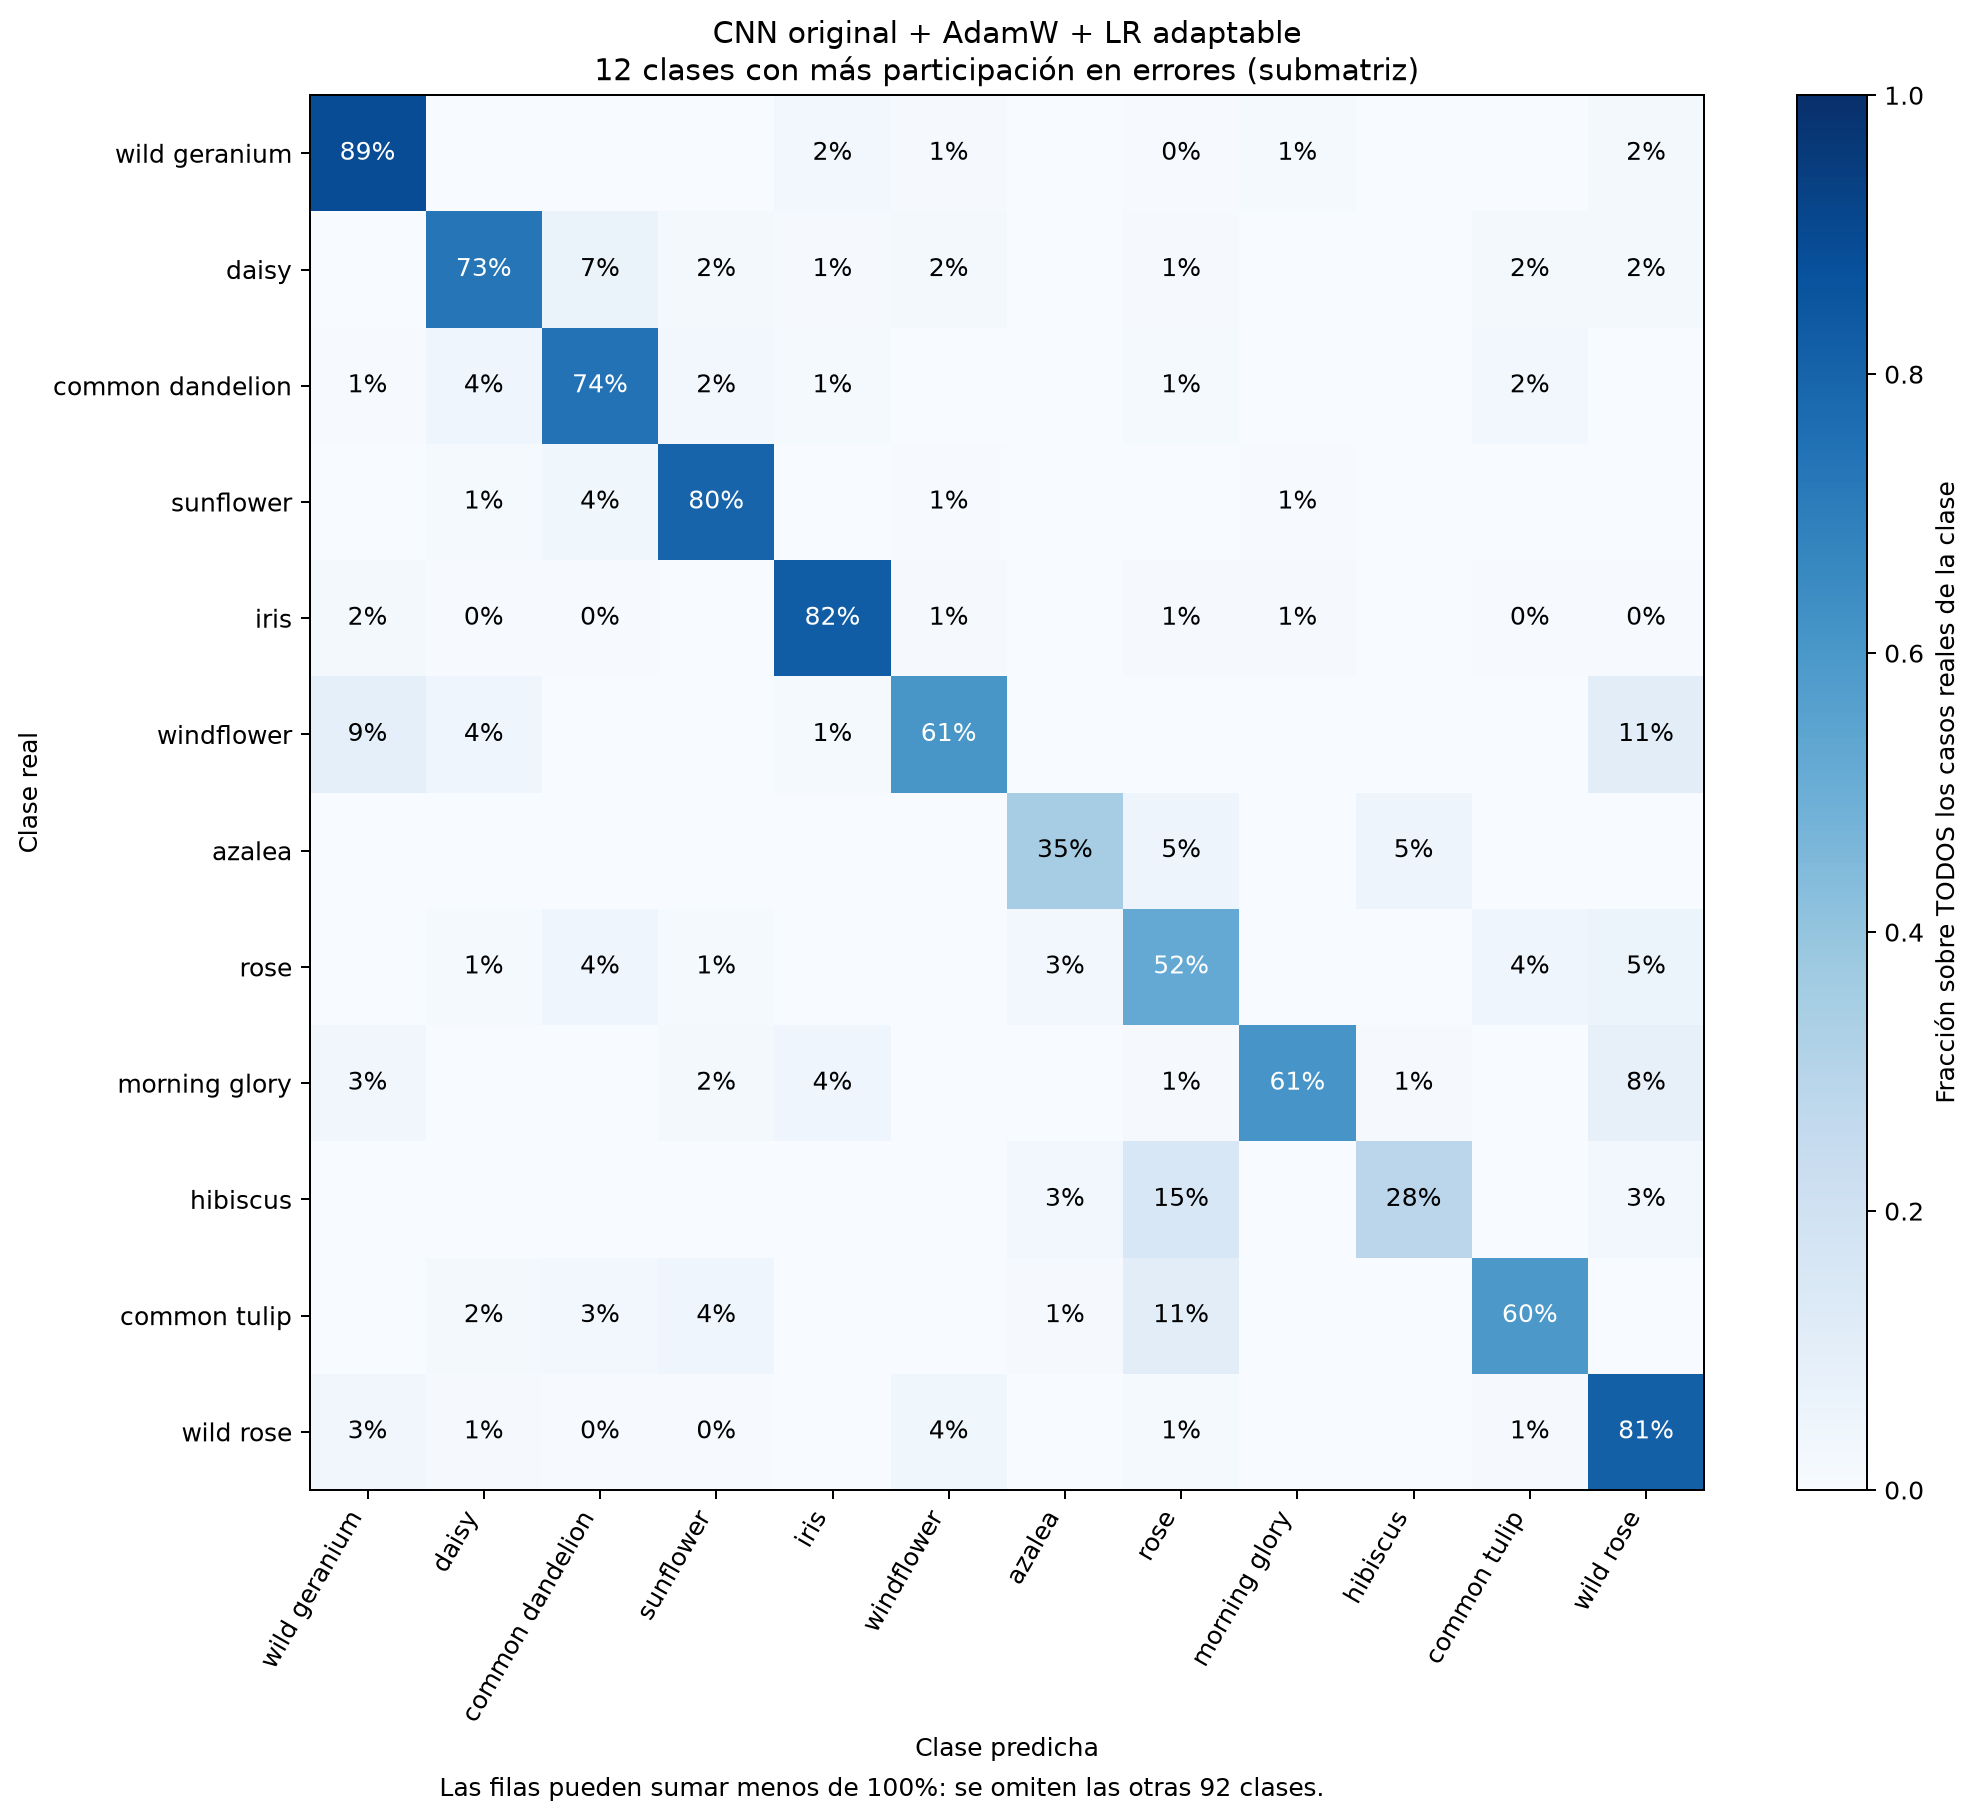

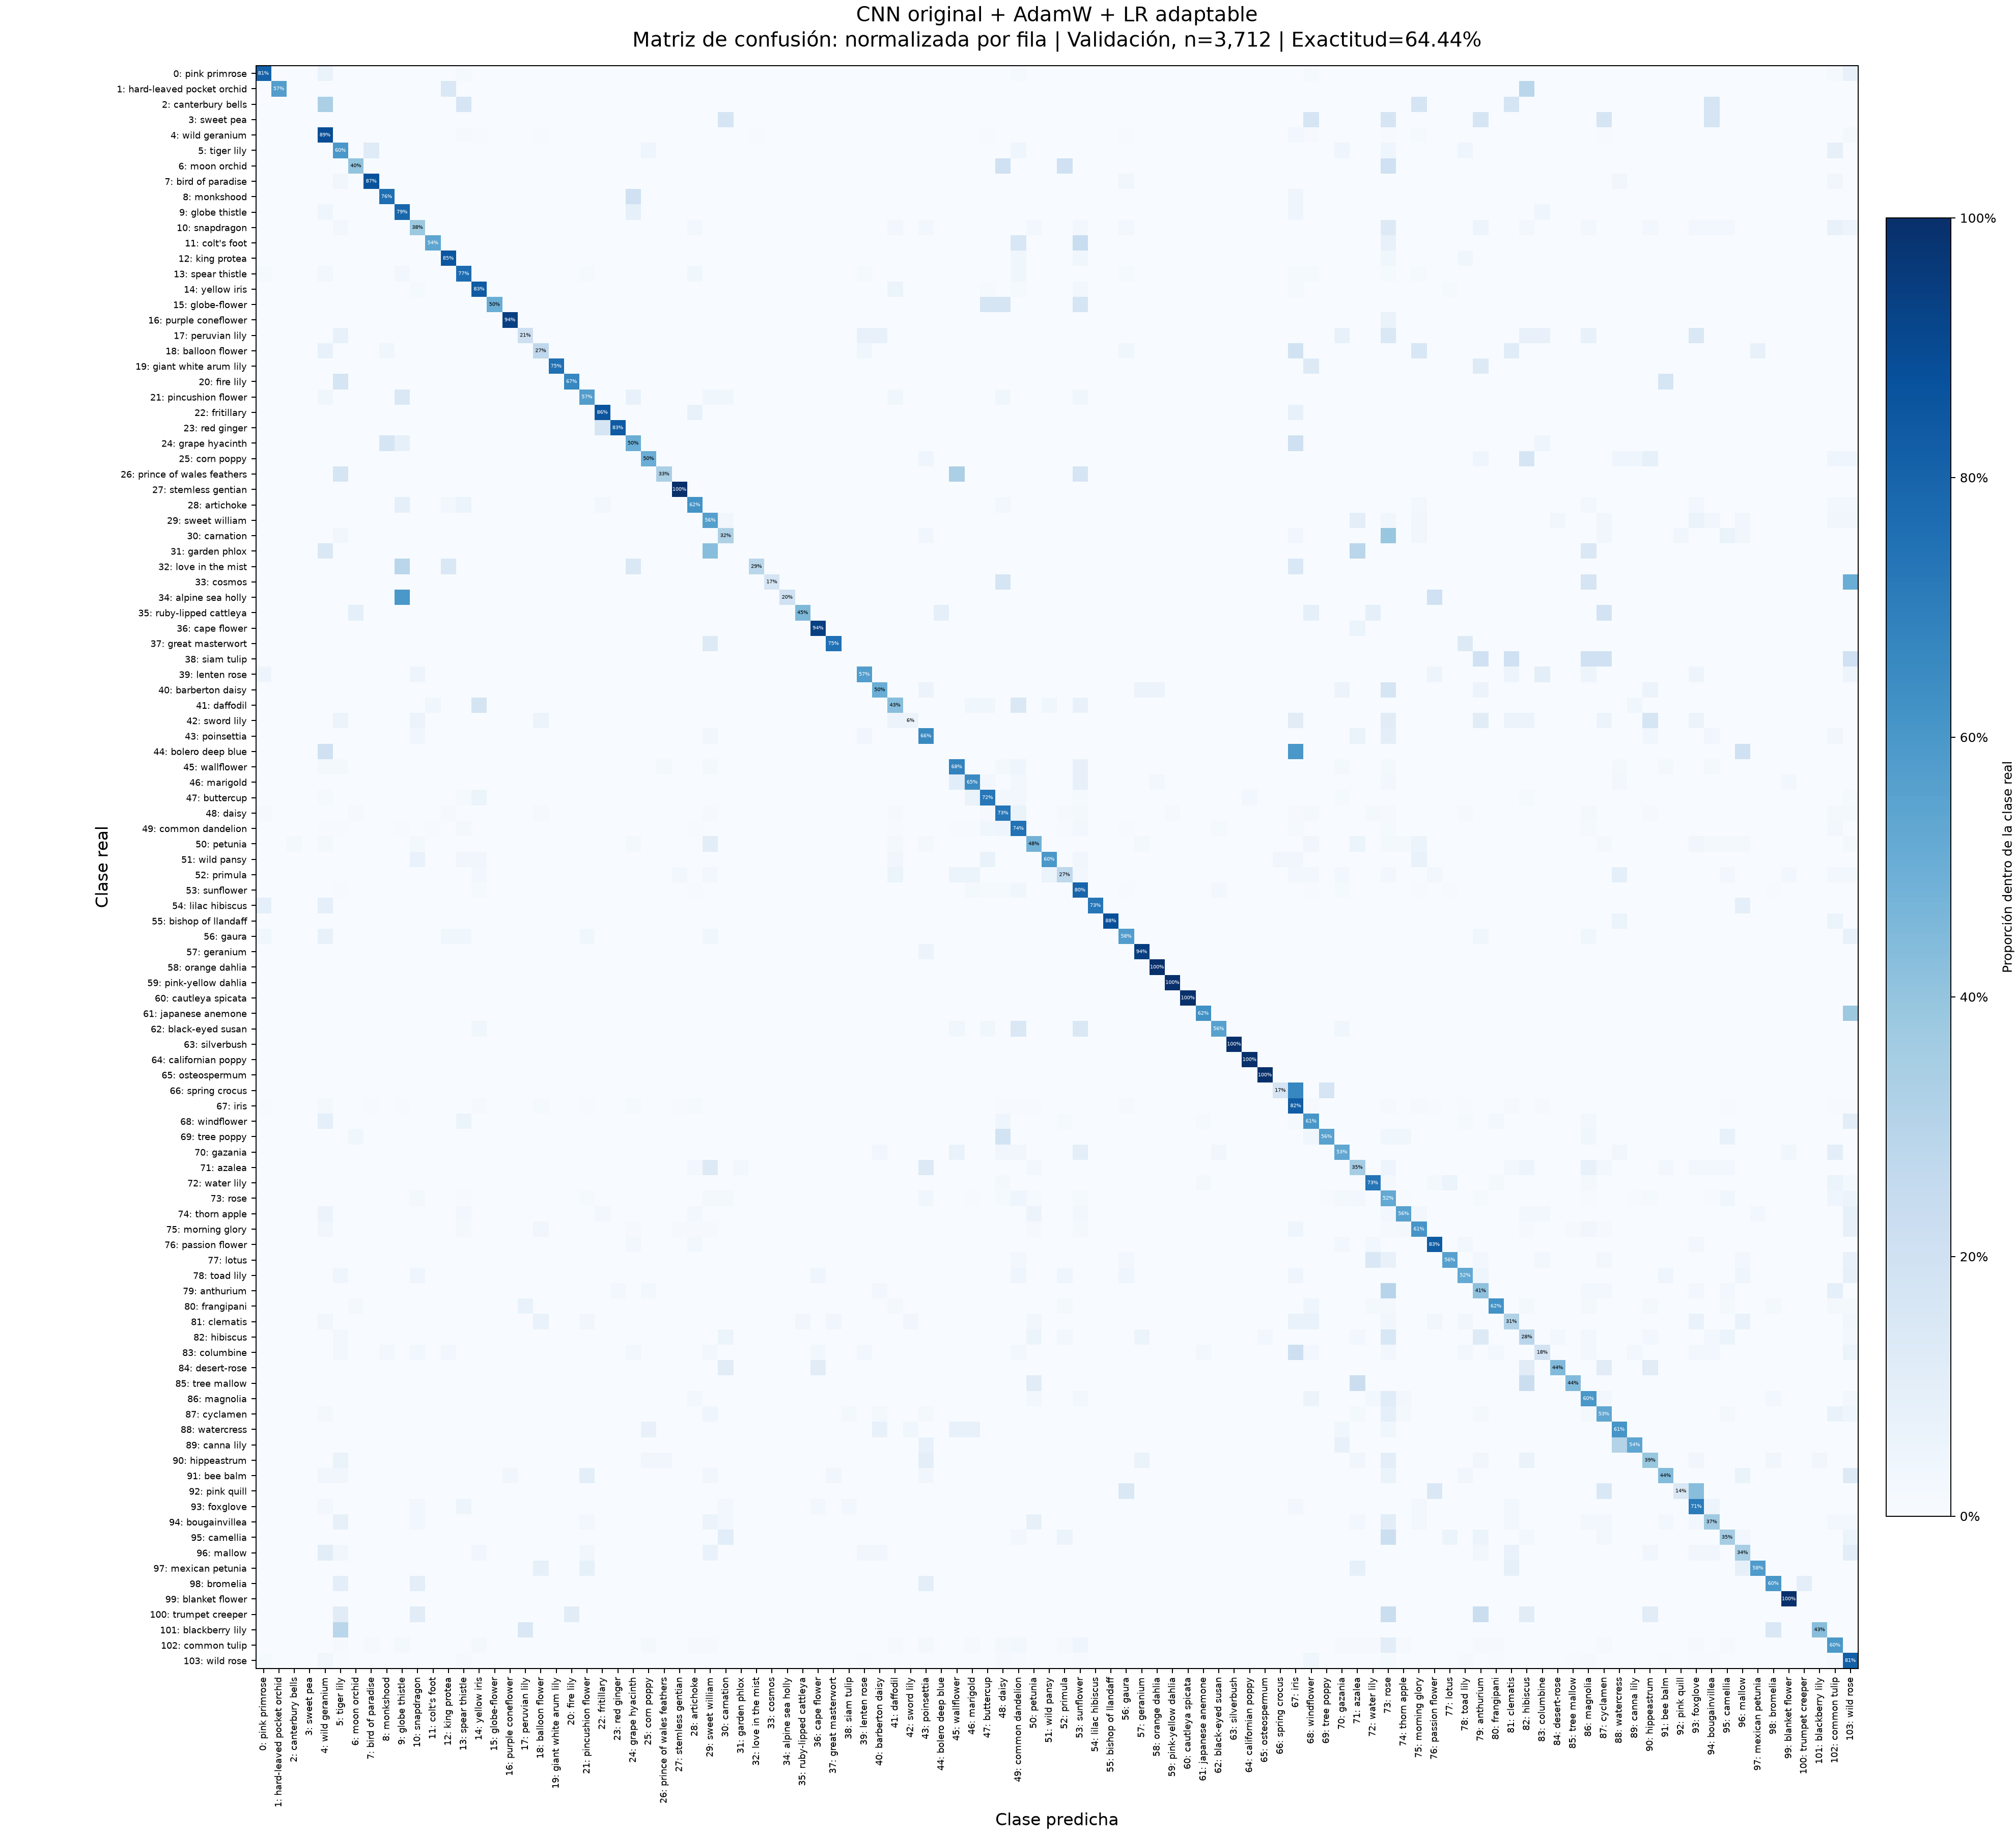

Filas reales, columnas predichas; diagonal normalizada=recall. La submatriz omite otras clases.


In [11]:
evaluation=json.loads((REPORT/"correcciones_etapa4/evaluacion_seleccionado.json").read_text(encoding="utf-8"))
display(pd.DataFrame(evaluation["confusions"][:6]))
display(Image(filename=str(A4/"figures/cnn_regularizada/confusiones_principales.png"),width=900))
display(Image(filename=str(A4/"figures/cnn_regularizada/confusion_matrix_normalized.png"),width=1100))
print("Filas reales, columnas predichas; diagonal normalizada=recall. La submatriz omite otras clases.")

## 9. Conclusiones y límites
La CNN aprovecha estructura espacial con menos parámetros que la MLP ensayada. El baseline se conserva con su bajo ajuste y sin afirmar que una MLP sea incapaz de aprender imágenes. La CNN ampliada no mejora esta corrida y sus curvas sugieren sobreajuste. Se selecciona CNN AdamW/LR dentro de A4, sin presentar su pequeña diferencia de F1 como significativa.

El par F respalda cuantitativamente la intervención conjunta de regularización; época 34 revela que su ventaja final no existe durante toda la trayectoria. Se separan familias, checkpoints y protocolos de train para evitar mezclar métricas.

**Verificado aquí:** métricas desde predicciones, matrices, clases, épocas y fuentes históricas. **No repetido:** entrenamiento, inferencia sobre TFRecords, paridad de logits, pérdidas y train limpio; faltan datos/frameworks. Los checkpoints A4 existentes y su prueba de exportación son evidencia histórica. No hay test independiente ni estimación entre semillas.

Para regenerar tablas: `python -m scripts.build_avance4_report`. Para regularización: `python reports/entregable_4/correcciones_etapa3/analizar_regularizacion.py`. Pruebas ligeras: `python -m unittest tests.test_avance4_evidence tests.test_avance4_regularization tests.test_avance4_report -v`. La suite completa pytest requiere TensorFlow; no debe declararse aprobada sin ejecutarla.

PDF: compilar `reports/entregable_4/equipo_proyecto_avance4.tex` con Tectonic desde esa carpeta. Fuentes/IDs/hashes se conservan en los manifiestos de corrección. El ZIP actualizado contiene este notebook, PDF y evidencia; no datasets ni checkpoints nuevos.